Every strategy so far bought or sold assets and bet on where their prices would go. Options are different: they pay off according to *how far* a price moves, so their prices carry the market's view of future **volatility**. They are also where quantitative finance began as a mathematical discipline: the 1973 Black–Scholes–Merton formula won a Nobel prize and created a trillion-dollar industry.

This project builds option pricing from scratch, starting from a single coin flip, and ends with a modern idea: training a neural network to imitate an expensive pricing model so that calibrating it to the market takes milliseconds. Along the way it asks a trading question with 33 years of data behind it: is selling volatility a free lunch?

:::eli5
An option is an insurance policy on a price. A **call** lets you buy at a fixed price (the *strike*) later; a **put** lets you sell at the strike. If the price ends up on the wrong side, you simply don't use it, so an option can never be worth less than zero. How much should the insurance cost? It depends on how wild the price is likely to be: insuring a calm price is cheap, insuring a wild one is expensive. That “wildness” is **volatility**, and option prices are the market's forecast of it.
:::

## Look at the big picture

Frame the project the way a derivatives desk would before writing any code.

- **Objective.** (1) Price and hedge options consistently with the market; (2) keep a model calibrated to today's option prices, fast enough to recalibrate many times a day; (3) decide whether systematically *selling* volatility is worth the risk.
- **Performance measures.** Pricing error in implied-volatility points, compared with a typical bid–ask spread of about half a vol point for liquid SPY options; the standard deviation of hedging P&L relative to the premium; for the volatility-selling strategy, the Sharpe ratio *and* the skewness and worst month.
- **Assumptions to check.** Black–Scholes assumes constant volatility, continuous frictionless trading and lognormal prices. Each will be tested against data: the smile (volatility is not constant), the hedging simulation (trading is discrete), the variance risk premium (the volatility you pay is not the volatility you get).

## Setup and data

Two datasets. A snapshot of the SPY option chain at the close of 3 November 2026 for six expiries from 17 days to 13 months (2,486 contracts, from Yahoo Finance), and daily SPY prices, the VIX index and the three-month Treasury bill rate since 1990.

In [1]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.stats import norm
from scipy.optimize import least_squares
import json, time, warnings
warnings.filterwarnings("ignore")

mpl.rc("axes", labelsize=12, titlesize=13); mpl.rc("figure", dpi=110)
IMAGES = Path("images"); IMAGES.mkdir(exist_ok=True)
DATA = Path("datasets")
def save_fig(name):
    plt.tight_layout(); plt.savefig(IMAGES / f"{name}.png", dpi=150, bbox_inches="tight")
R = {}
rng = np.random.default_rng(8)

daily = pd.read_csv(DATA / "spy_vix_daily.csv", index_col="date", parse_dates=True)
chain = pd.read_csv(DATA / "spy_options.csv", parse_dates=["lastTradeDate"])
S0 = daily["spy_close"].iloc[-1]; r0 = daily["tbill3m"].iloc[-1] / 100
print(f"SPY close {daily.index[-1].date()}: {S0:.2f}, VIX {daily['vix'].iloc[-1]:.2f}, 3-month T-bill {r0:.2%}")
print(chain.groupby(["expiry", "type"]).size().unstack())

SPY close 2026-11-03: 754.35, VIX 20.83, 3-month T-bill 4.03%
type        call  put
expiry               
2026-11-20   224  201
2026-12-18   255  241
2027-01-15   234  185
2027-03-19   198  138
2027-06-17   217  179
2027-12-17   228  186


:::trap
The snapshot was taken before the next day's open, so bid and ask quotes are zero and Yahoo's own implied volatilities are meaningless. We use each contract's **last trade price**, keep only contracts that traded in the last hour of 3 November, and compute every implied volatility ourselves. Last prices are not perfectly synchronised with the SPY close; professional work uses time-stamped bid–ask midquotes. Expect a little noise.
:::

## What an option is worth at expiry, and one law that needs no model

:::math
At expiry $T$, with the underlying at $S_T$ and strike $K$, a call pays $(S_T - K)^+ = \max(S_T - K, 0)$ and a put pays $(K - S_T)^+$. Their difference is $(S_T-K)^+ - (K-S_T)^+ = S_T - K$, whatever happens. A portfolio “long a call, short a put” is therefore the same as a forward contract, and the same payoff must have the same price today:

$$C - P = D\,(F - K),$$

where $D = e^{-rT}$ is the discount factor and $F$ the forward price of the underlying for delivery at $T$. This is **put–call parity**. It needs no model of how prices move, only the absence of arbitrage. For a stock paying a dividend yield $q$, $F = S_0 e^{(r-q)T}$.
:::

Parity runs both ways: given call and put prices at the same strikes, it tells us the forward price the market is using, which absorbs interest rates and expected dividends without our having to estimate them.

In [2]:
chain["ltd"] = chain["lastTradeDate"].dt.tz_convert("America/New_York")
asof = pd.Timestamp("2026-11-03 16:00")
fresh = chain[(chain["ltd"].dt.strftime("%Y-%m-%d") == "2026-11-03") & (chain["ltd"].dt.hour >= 15)].copy()
fresh["T"] = ((pd.to_datetime(fresh["expiry"]) + pd.Timedelta(hours=16)) - asof).dt.total_seconds() / (365 * 86400)

fwd = {}
for e, g in fresh.groupby("expiry"):
    T = g["T"].iloc[0]; D = np.exp(-r0 * T)
    c = g[g["type"] == "call"].set_index("strike")["lastPrice"]; p = g[g["type"] == "put"].set_index("strike")["lastPrice"]
    ks = c.index.intersection(p.index); ks = ks[abs(ks / S0 - 1) < 0.05]          # strikes near the money
    F_k = ks + (c[ks] - p[ks]) / D                                                # parity, strike by strike
    fwd[e] = dict(T=T, D=D, F=float(np.median(F_k)), n=len(ks), spread=float(np.std(F_k)))
fwd = pd.DataFrame(fwd).T
fwd["carry r-q"] = np.log(fwd["F"] / S0) / fwd["T"]
print(fwd.astype(float).round(4))
R["carry_1y"] = f"{fwd['carry r-q'].iloc[-1]:.1%}"; R["r0"] = f"{r0:.2%}"

                 T       D         F     n  spread  carry r-q
2026-11-20  0.0466  0.9981  755.7477  34.0  0.3069     0.0397
2026-12-18  0.1233  0.9950  757.1884  24.0  0.4320     0.0305
2027-01-15  0.2000  0.9920  758.7299  13.0  0.4281     0.0289
2027-03-19  0.3726  0.9851  763.7182  10.0  0.6113     0.0331
2027-06-17  0.6192  0.9754  770.1606   8.0  0.7410     0.0335
2027-12-17  1.1205  0.9558  785.4901   3.0  0.5344     0.0361


The forward prices implied by parity agree with one another to well under a dollar per strike (the `spread` column). The implied carry $r - q$ for the longest expiry is 3.6%, against a T-bill rate of 4.03% and SPY's dividend yield of a little over 1%; with only a few liquid strike pairs that far out, the estimate is noisy.

## Pricing by replication: the binomial tree

:::math
**One step.** Today the stock is at $S$; tomorrow it is $uS$ or $dS$. A call pays $C_u$ or $C_d$. Buy $\Delta$ shares and borrow $B$, and choose them so the portfolio pays exactly what the call pays in both states:

$$\Delta uS - B e^{r\,dt} = C_u,\qquad \Delta dS - Be^{r\,dt} = C_d \quad\Rightarrow\quad \Delta = \frac{C_u - C_d}{(u-d)S}.$$

The call must cost what the replicating portfolio costs, $C = \Delta S - B$, otherwise there is an arbitrage. Rearranging gives

$$C = e^{-r\,dt}\left[p\,C_u + (1-p)\,C_d\right],\qquad p = \frac{e^{r\,dt} - d}{u - d}.$$

The price is a discounted *expectation*, but under the probability $p$, not the real-world probability of an up move. Nobody's opinion about where the stock is going appears anywhere: only volatility (through $u$ and $d$) matters. $p$ is the **risk-neutral probability**.

**Many steps.** Cox, Ross and Rubinstein (1979) chose $u = e^{\sigma\sqrt{dt}}$, $d = 1/u$, so that the tree's volatility is $\sigma$. Repeat the one-step argument backwards from expiry through $n$ steps. For an **American** option, at each node take the larger of the continuation value and immediate exercise.
:::

In [3]:
def crr(S, K, T, r, sigma, n, kind="call", american=False, q=0.0):
    dt = T / n; u = np.exp(sigma * np.sqrt(dt)); d = 1 / u
    p = (np.exp((r - q) * dt) - d) / (u - d); disc = np.exp(-r * dt)
    ST = S * u ** np.arange(n, -1, -1) * d ** np.arange(0, n + 1)      # terminal prices, top to bottom
    pay = (lambda s: np.maximum(s - K, 0)) if kind == "call" else (lambda s: np.maximum(K - s, 0))
    V = pay(ST)
    for j in range(n - 1, -1, -1):
        V = disc * (p * V[:-1] + (1 - p) * V[1:])
        if american:
            Sj = S * u ** np.arange(j, -1, -1) * d ** np.arange(0, j + 1)
            V = np.maximum(V, pay(Sj))
    return V[0]

print("one step:", round(crr(100, 100, 1, 0.04, 0.2, 1), 4), "  1,000 steps:", round(crr(100, 100, 1, 0.04, 0.2, 1000), 4))

one step: 11.7319   1,000 steps: 9.9231


## The Black–Scholes formula

:::math
As the number of steps grows, the tree's terminal distribution becomes lognormal: under the risk-neutral measure, $\ln S_T \sim \mathcal N\!\left(\ln F - \tfrac12\sigma^2 T,\ \sigma^2 T\right)$. The call price is the discounted expected payoff, $C = D\,\mathbb E[(S_T - K)^+]$. Splitting the integral where $S_T > K$ and completing the square gives

$$C = D\left[F\,\Phi(d_1) - K\,\Phi(d_2)\right],\qquad d_{1,2} = \frac{\ln(F/K) \pm \tfrac12\sigma^2 T}{\sigma\sqrt T},$$

and the put follows from parity. The derivatives of the price, the **Greeks**, measure its sensitivities. With $\varphi$ the normal density and $S$ the spot ($F = Se^{(r-q)T}$):

| Greek | meaning | call |
|---|---|---|
| delta $\Delta$ | $\partial C/\partial S$, the hedge ratio | $e^{-qT}\Phi(d_1)$ |
| gamma $\Gamma$ | $\partial^2 C/\partial S^2$, how fast delta changes | $e^{-qT}\varphi(d_1)/(S\sigma\sqrt T)$ |
| vega $\mathcal V$ | $\partial C/\partial\sigma$ | $Se^{-qT}\varphi(d_1)\sqrt T$ |
| theta $\Theta$ | $\partial C/\partial t$, time decay | $-\frac{Se^{-qT}\varphi(d_1)\sigma}{2\sqrt T} - rKe^{-rT}\Phi(d_2) + qSe^{-qT}\Phi(d_1)$ |

Black and Scholes (1973) and Merton (1973) reached the same formula differently: a portfolio of the option and $-\Delta$ shares has no risk over an instant, so it must earn the risk-free rate. That gives a partial differential equation, $\Theta + (r-q)S\Delta + \tfrac12\sigma^2S^2\Gamma = rC$, whose solution is the formula above.
:::

In [4]:
def bs(S, K, T, r, sigma, kind="call", q=0.0):
    S, K, T, sigma = map(np.asarray, (S, K, T, sigma))
    F, D = S * np.exp((r - q) * T), np.exp(-r * T)
    sT = sigma * np.sqrt(T); d1 = (np.log(F / K) + 0.5 * sT**2) / sT; d2 = d1 - sT
    if kind == "call":
        return D * (F * norm.cdf(d1) - K * norm.cdf(d2))
    return D * (K * norm.cdf(-d2) - F * norm.cdf(-d1))

def greeks(S, K, T, r, sigma, q=0.0):
    sT = sigma * np.sqrt(T); d1 = (np.log(S / K) + (r - q + 0.5 * sigma**2) * T) / sT; d2 = d1 - sT
    eq = np.exp(-q * T)
    return dict(delta=eq * norm.cdf(d1), gamma=eq * norm.pdf(d1) / (S * sT), vega=S * eq * norm.pdf(d1) * np.sqrt(T),
                theta=-S * eq * norm.pdf(d1) * sigma / (2 * np.sqrt(T)) - r * K * np.exp(-r * T) * norm.cdf(d2) + q * S * eq * norm.cdf(d1))

g = greeks(100, 100, 1, 0.04, 0.2); h = 1e-3
fd = dict(delta=(bs(100 + h, 100, 1, .04, .2) - bs(100 - h, 100, 1, .04, .2)) / (2 * h),
          gamma=(bs(100 + h, 100, 1, .04, .2) - 2 * bs(100, 100, 1, .04, .2) + bs(100 - h, 100, 1, .04, .2)) / h**2,
          vega=(bs(100, 100, 1, .04, .2 + h) - bs(100, 100, 1, .04, .2 - h)) / (2 * h),
          theta=-(bs(100, 100, 1 + h, .04, .2) - bs(100, 100, 1 - h, .04, .2)) / (2 * h))
print(pd.DataFrame({"formula": g, "finite difference": fd}).round(5))

        formula  finite difference
delta   0.61791            0.61791
gamma   0.01907            0.01907
vega   38.13878           38.13876
theta  -5.88852           -5.88852


The formulas agree with finite differences of the price to five decimals. Now the tree against the formula, and what early exercise is worth:

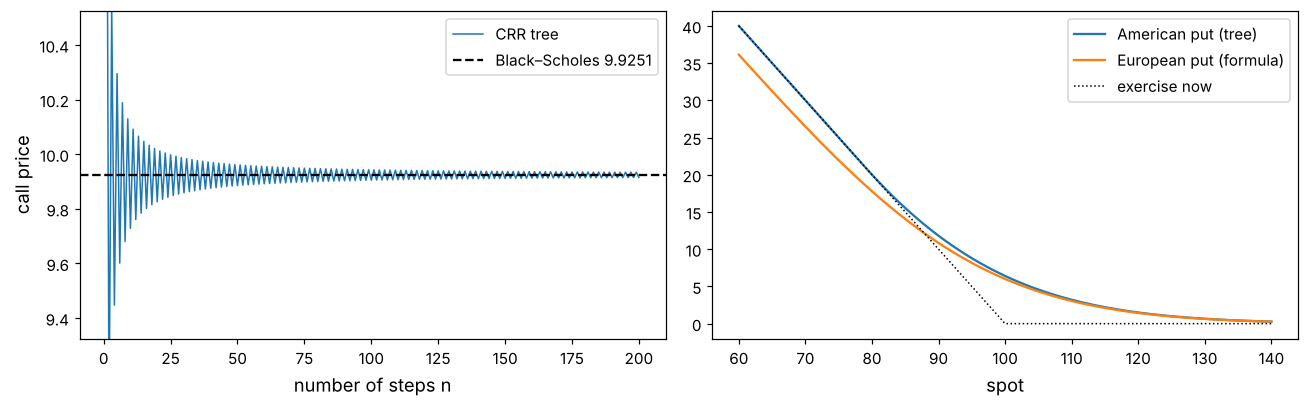

In [5]:
ns = np.arange(1, 201)
tree = [crr(100, 100, 1, 0.04, 0.2, n) for n in ns]
exact = float(bs(100, 100, 1, 0.04, 0.2))
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].plot(ns, tree, lw=1, label="CRR tree"); ax[0].axhline(exact, color="k", ls="--", label=f"Black–Scholes {exact:.4f}")
ax[0].set_xlabel("number of steps n"); ax[0].set_ylabel("call price"); ax[0].set_ylim(exact - 0.6, exact + 0.6); ax[0].legend()
Ss = np.linspace(60, 140, 81)
eu = bs(Ss, 100, 1, 0.04, 0.2, "put"); am = np.array([crr(s, 100, 1, 0.04, 0.2, 400, "put", american=True) for s in Ss])
ax[1].plot(Ss, am, label="American put (tree)"); ax[1].plot(Ss, eu, label="European put (formula)")
ax[1].plot(Ss, np.maximum(100 - Ss, 0), "k:", lw=1, label="exercise now"); ax[1].set_xlabel("spot"); ax[1].legend()
save_fig("tree_bs"); plt.show()
R["tree_err"] = f"{abs(tree[-1] - exact):.4f}"
R["am_prem"] = f"{crr(90, 100, 1, 0.04, 0.2, 400, 'put', american=True) - float(bs(90, 100, 1, 0.04, 0.2, 'put')):.2f}"

![Figure 8-1. Left: the binomial price converges to Black–Scholes as the number of steps grows, zig-zagging between odd and even n. Right: an American put is worth more than a European one because it can be exercised early; deep in the money it is worth exactly its exercise value.](images/tree_bs.png)

With 200 steps the tree is within 0.0099 of the formula. For a put with strike 100 and spot 90, the right to exercise early is worth 0.97: deep in the money, the holder would rather receive the strike now and earn interest on it.

## Monte Carlo pricing

When no formula exists (the payoff depends on the whole path, or the model is complicated), simulate many risk-neutral paths, average the discounted payoffs, and report a **standard error**. Two classic tricks reduce the error without more paths.

:::math
- **Antithetic variates.** For every normal draw $Z$, also use $-Z$. The two payoffs are negatively correlated, so their average has a smaller variance.
- **Control variates.** Find a quantity $Y$ whose expectation is known and which is correlated with the payoff $X$. Here $\mathbb E[D\,S_T] = S_0e^{-qT}$. Then $X - b\,(Y - \mathbb E Y)$ has the same mean and variance $\mathrm{Var}(X)(1 - \rho_{XY}^2)$ for the best $b = \mathrm{Cov}(X,Y)/\mathrm{Var}(Y)$.
:::

In [6]:
def mc_call(S, K, T, r, sigma, n_paths, method="plain", seed=0):
    z = np.random.default_rng(seed).standard_normal(n_paths)
    ST = lambda zz: S * np.exp((r - 0.5 * sigma**2) * T + sigma * np.sqrt(T) * zz)
    D = np.exp(-r * T)
    if method == "antithetic":
        X = 0.5 * D * (np.maximum(ST(z) - K, 0) + np.maximum(ST(-z) - K, 0))
    else:
        X = D * np.maximum(ST(z) - K, 0)
        if method == "control":
            Y = D * ST(z); b = np.cov(X, Y)[0, 1] / Y.var(); X = X - b * (Y - S)
    return X.mean(), X.std(ddof=1) / np.sqrt(n_paths)

rows = {m: mc_call(100, 100, 1, 0.04, 0.2, 100_000, m) for m in ["plain", "antithetic", "control"]}
mc_tab = pd.DataFrame(rows, index=["price", "std error"]).T; mc_tab["error vs formula"] = mc_tab["price"] - exact
mc_tab["paths for same error as control"] = (100_000 * (mc_tab["std error"] / mc_tab.loc["control", "std error"])**2).round(-3)
print(mc_tab.round(4))
R["cv_factor"] = f"{(mc_tab.loc['plain', 'std error'] / mc_tab.loc['control', 'std error'])**2:.0f}"

             price  std error  error vs formula  \
plain       9.9113     0.0456           -0.0138   
antithetic  9.9260     0.0234            0.0009   
control     9.9232     0.0181           -0.0019   

            paths for same error as control  
plain                              636000.0  
antithetic                         168000.0  
control                            100000.0  


The control variate cuts the variance by a factor of about 6: plain Monte Carlo would need that many times as many paths for the same accuracy. Monte Carlo earns its keep on path-dependent payoffs. A **down-and-out call** dies if the price ever touches a barrier below the spot, so it is cheaper than a plain call:

In [7]:
def mc_down_and_out(S, K, H, T, r, sigma, n_paths=50_000, steps=252, seed=1):
    dt = T / steps; z = np.random.default_rng(seed).standard_normal((n_paths, steps))
    logS = np.log(S) + np.cumsum((r - 0.5 * sigma**2) * dt + sigma * np.sqrt(dt) * z, axis=1)
    alive = logS.min(axis=1) > np.log(H)
    vanilla = np.exp(-r * T) * np.maximum(np.exp(logS[:, -1]) - K, 0)
    X = vanilla * alive
    return X.mean(), vanilla.mean(), alive.mean()

for H in [70, 80, 90, 95]:
    p, p_van, surv = mc_down_and_out(100, 100, H, 1, 0.04, 0.2)
    print(f"barrier {H}: down-and-out {p:.3f}  vs plain call {p_van:.3f} on the same paths  (discount {p_van - p:.3f}),  {surv:.0%} of paths survive")

barrier 70: down-and-out 9.980  vs plain call 9.980 on the same paths  (discount 0.000),  94% of paths survive


barrier 80: down-and-out 9.907  vs plain call 9.980 on the same paths  (discount 0.074),  78% of paths survive


barrier 90: down-and-out 8.515  vs plain call 9.980 on the same paths  (discount 1.466),  46% of paths survive


barrier 95: down-and-out 5.884  vs plain call 9.980 on the same paths  (discount 4.096),  26% of paths survive


## Implied volatility and the smile

Black–Scholes has one unobservable input, $\sigma$. Turn the formula around: given a market price, find the $\sigma$ that reproduces it. That is the **implied volatility**, the market's price quoted in units everyone can compare.

:::math
The call price increases strictly with $\sigma$ (vega is positive), so the inverse exists and **bisection** always finds it: start with $[\sigma_{lo}, \sigma_{hi}]$, evaluate the price at the midpoint, keep the half that brackets the market price. Each step halves the interval, so 60 steps give 18 digits. Newton's method, $\sigma \leftarrow \sigma - (C(\sigma) - C_{mkt})/\mathcal V$, is faster but can fail far from the money where vega is tiny. Bisection vectorises perfectly: all options are solved at once.
:::

In [8]:
def bs_fwd_call(F, K, T, sigma):
    """undiscounted call price on a forward"""
    sT = sigma * np.sqrt(T); d1 = (np.log(F / K) + 0.5 * sT**2) / sT
    return F * norm.cdf(d1) - K * norm.cdf(d1 - sT)

def implied_vol(c, F, K, T, n_iter=60):
    """undiscounted call prices -> implied volatility, by vectorised bisection"""
    c, F, K, T = np.broadcast_arrays(*(np.asarray(v, float) for v in (c, F, K, T)))
    lo, hi = np.full(c.shape, 1e-4), np.full(c.shape, 5.0)
    for _ in range(n_iter):
        mid = 0.5 * (lo + hi); above = bs_fwd_call(F, K, T, mid) > c
        hi = np.where(above, mid, hi); lo = np.where(above, lo, mid)
    iv = 0.5 * (lo + hi)
    return np.where((c <= np.maximum(F - K, 0) + 1e-12) | (c >= F), np.nan, iv)   # outside no-arbitrage bounds

print("round trip:", implied_vol(bs_fwd_call(100, np.array([80, 100, 120]), 0.5, 0.23), 100, np.array([80, 100, 120]), 0.5))

round trip: [0.23 0.23 0.23]


For each expiry we use out-of-the-money options only (puts below the forward, calls above), because they trade most and their prices are least affected by the stale-price problem. Each put is converted into the equivalent call by parity before inverting.

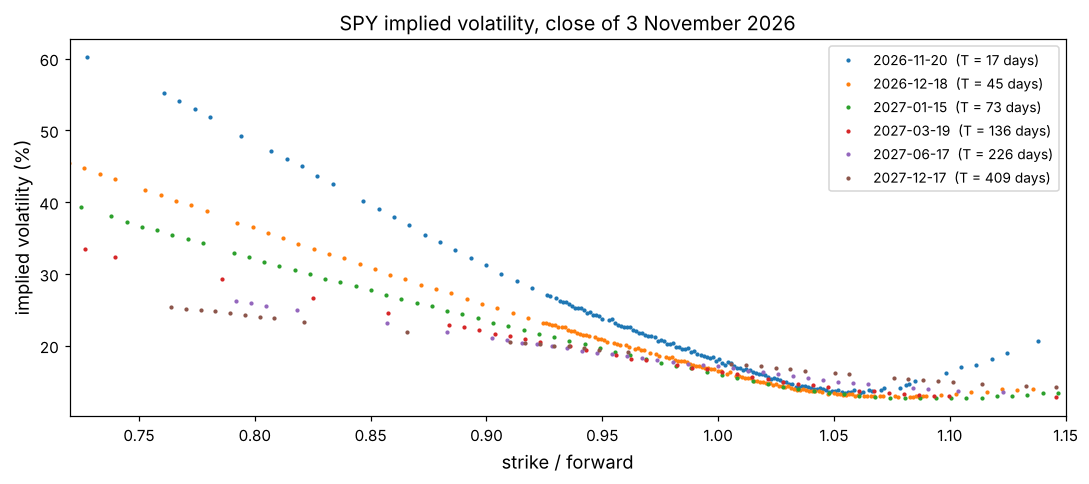

In [9]:
smile = []
for e, g in fresh.groupby("expiry"):
    T, D, F = fwd.loc[e, ["T", "D", "F"]].astype(float)
    g = g[((g["type"] == "put") & (g["strike"] < F)) | ((g["type"] == "call") & (g["strike"] >= F))].copy()
    und = np.where(g["type"] == "call", g["lastPrice"], g["lastPrice"] + D * (F - g["strike"])) / D
    g["iv"] = implied_vol(und, F, g["strike"].to_numpy(), T); g["F"] = F; g["x"] = np.log(g["strike"] / F)
    smile.append(g)
smile = pd.concat(smile).dropna(subset=["iv"])
smile = smile[smile["x"].abs() < 0.35]

fig, ax = plt.subplots(figsize=(10, 4.5))
for e, g in smile.groupby("expiry"):
    ax.plot(g["strike"] / g["F"], 100 * g["iv"], ".", ms=3.5, label=f"{e}  (T = {g['T'].iloc[0] * 365:.0f} days)")
ax.set_xlabel("strike / forward"); ax.set_ylabel("implied volatility (%)"); ax.set_xlim(0.72, 1.15); ax.legend(fontsize=9)
ax.set_title("SPY implied volatility, close of 3 November 2026")
save_fig("spy_smile"); plt.show()

atm = smile.loc[smile["expiry"] == "2026-12-18"].iloc[lambda g: (g["x"].abs()).argsort()[:3]]["iv"].mean()
R["atm_1m"] = f"{atm:.1%}"; R["vix0"] = f"{daily['vix'].iloc[-1] / 100:.1%}"
p90 = smile[(smile["expiry"] == "2026-12-18")].iloc[lambda g: (g["strike"] / g["F"] - 0.9).abs().argsort()[:1]]["iv"].iloc[0]
R["iv_90"] = f"{p90:.1%}"

![Figure 8-2. The volatility skew of SPY options. If Black–Scholes were right, every option on SPY would have the same implied volatility and the points would lie on one flat line. Instead, protection against falls (low strikes) is expensive, and the skew is steepest for the shortest expiry.](images/spy_smile.png)

Black–Scholes assumes one constant volatility, so if it were the true model every option on SPY would have the same implied volatility. The market disagrees. The one-month at-the-money implied volatility is 16.6%, while a put struck 10% below the forward has 25.8%. Since the crash of October 1987, when the S&P 500 fell 20% in a day, investors pay extra for crash protection, and the **skew** has never gone away.

:::quant
The VIX index, 20.8% that day, is not the at-the-money implied volatility (16.6%). It is computed from a whole strip of out-of-the-money S&P 500 options, so it includes the expensive downside puts: by construction, VIX² is the fair strike of a 30-day **variance swap**. That is why VIX is usually two or three points above at-the-money implied volatility, and why it is the right benchmark for the next section.
:::

## Delta hedging: where the option's value comes from

A bank that sells a call does not want to bet on the market. It **delta-hedges**: holds $\Delta$ shares against the short call and rebalances as $\Delta$ changes. If Black–Scholes were exactly true and rebalancing continuous, the hedged position would have zero risk and the premium would exactly pay for the hedge. With discrete rebalancing, some risk remains.

In [10]:
def hedge_pnl(sigma_true, sigma_implied, n_steps, n_paths=20_000, S=100.0, K=100.0, T=21 / 252, r=0.04, seed=3):
    """sell one call at the implied vol, delta-hedge n_steps times with implied-vol deltas; P&L at expiry"""
    dt = T / n_steps; z = np.random.default_rng(seed).standard_normal((n_paths, n_steps))
    St = np.full(n_paths, S); cash = np.full(n_paths, float(bs(S, K, T, r, sigma_implied)))
    delta = np.zeros(n_paths)
    for i in range(n_steps):
        tau = T - i * dt
        new_delta = greeks(St, K, tau, r, sigma_implied)["delta"]
        cash -= (new_delta - delta) * St; delta = new_delta
        cash *= np.exp(r * dt)
        St = St * np.exp((r - 0.5 * sigma_true**2) * dt + sigma_true * np.sqrt(dt) * z[:, i])
    return cash + delta * St - np.maximum(St - K, 0)

prem = float(bs(100, 100, 21 / 252, 0.04, 0.2))
rows = []
for n in [1, 5, 21, 84, 336]:
    pnl = hedge_pnl(0.2, 0.2, n)
    rows.append((n, pnl.mean(), pnl.std(), pnl.std() / prem))
hedge_tab = pd.DataFrame(rows, columns=["rebalances in 21 days", "mean P&L", "std P&L", "std / premium"]).set_index("rebalances in 21 days")
print(f"premium received: {prem:.3f}"); print(hedge_tab.round(3))
R["std_daily"] = f"{hedge_tab.loc[21, 'std / premium']:.0%}"; R["std_once"] = f"{hedge_tab.loc[1, 'std / premium']:.0%}"
R["std_4x"] = f"{hedge_tab.loc[84, 'std / premium']:.0%}"

premium received: 2.469
                       mean P&L  std P&L  std / premium
rebalances in 21 days                                  
1                         0.001    1.725          0.698
5                        -0.000    0.843          0.341
21                        0.000    0.430          0.174
84                        0.002    0.218          0.088
336                       0.001    0.109          0.044


The hedge is unbiased (mean P&L ≈ 0) and its error shrinks like $1/\sqrt{n}$: hedging daily leaves a standard deviation of 17% of the premium, four times a day 9%; hedging only once, at the start, leaves 70%. Now the interesting case: what if the volatility that actually happens differs from the one the option was sold at?

:::math
Over an instant, a delta-hedged short option earns its time decay and loses on the curvature: $d\Pi = -\tfrac12\,\Gamma S^2\,(\sigma_{\text{realised}}^2 - \sigma_{\text{implied}}^2)\,dt$. The seller of an option is **short volatility**: the seller wins when the market moves less than the implied volatility predicted and loses when it moves more, no matter in which direction. To first order the total P&L is $\mathcal V\,(\sigma_{\text{implied}} - \sigma_{\text{realised}})$.
:::

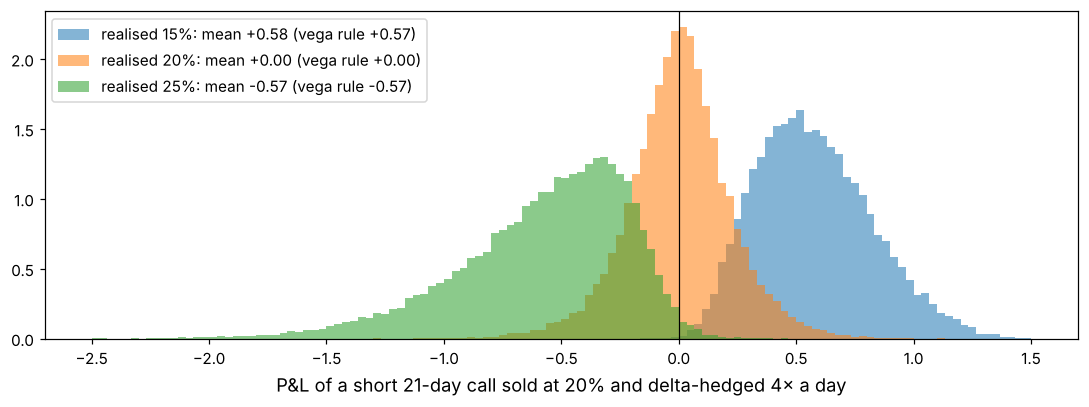

In [11]:
v = float(greeks(100, 100, 21 / 252, 0.04, 0.2)["vega"])
fig, ax = plt.subplots(figsize=(10, 3.8))
for s_true in [0.15, 0.20, 0.25]:
    pnl = hedge_pnl(s_true, 0.20, 84)
    ax.hist(pnl, bins=120, range=(-2.5, 1.5), alpha=0.55, density=True,
            label=f"realised {s_true:.0%}: mean {pnl.mean():+.2f} (vega rule {v * (0.20 - s_true):+.2f})")
ax.axvline(0, color="k", lw=0.8); ax.set_xlabel("P&L of a short 21-day call sold at 20% and delta-hedged 4× a day"); ax.legend()
save_fig("hedge_pnl"); plt.show()

![Figure 8-3. The hedged option seller's P&L depends on realised volatility, not on direction. Selling at 20% implied volatility makes money when the market moves at 15% and loses when it moves at 25%, close to the vega rule of thumb.](images/hedge_pnl.png)

## Project: is selling volatility a free lunch?

If options were priced at the volatility that later materialises, selling them would earn nothing on average. Do they? The cleanest test uses the variance swap: at the start of each month, sell one month of variance at the VIX level, and at the end pay the variance SPY actually realised.

:::math
A short variance swap struck at $K = \text{VIX}_t^2$ pays, after 21 trading days, $K - \text{RV}$ with $\text{RV} = \frac{252}{21}\sum_{i=1}^{21} r_{t+i}^2$ (daily log returns). No delta hedging or option model is needed; it is the pure bet “implied variance exceeds realised variance”. The average of $K - \text{RV}$ is the **variance risk premium**.
:::

404 months, 1993-02 to 2026-09
average implied vol 19.4%, average realised vol 15.7%
winning months 83%, Sharpe 0.58, skewness -6.4
worst months (in average-month gains):
date
2008-10-02   -68.0
2020-03-10   -58.0
2020-02-07   -23.0
2008-09-03   -23.0
Name: pnl, dtype: float64


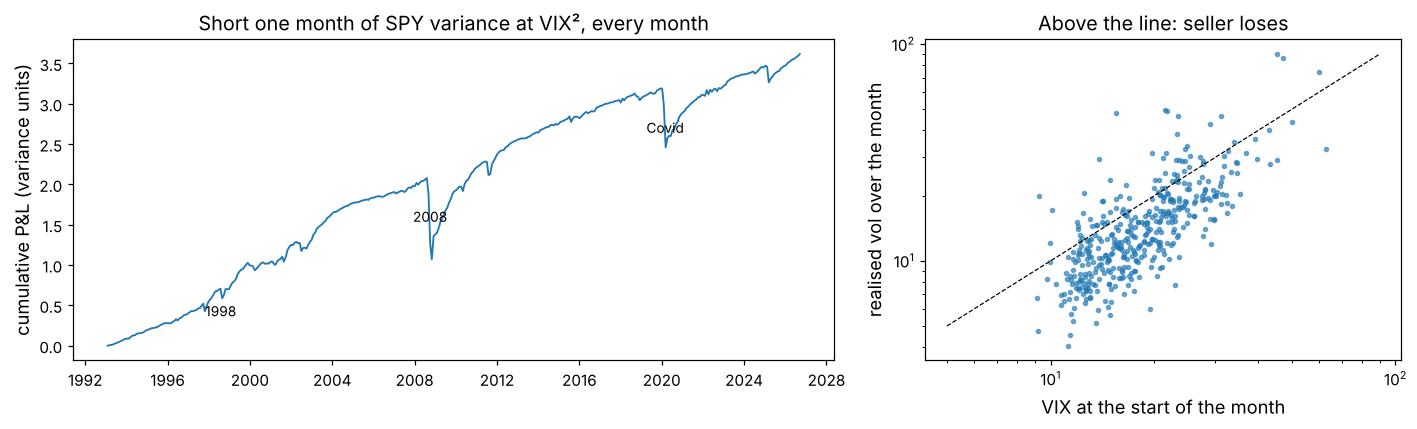

In [12]:
lr = np.log(daily["spy_adj"]).diff()
d = daily.dropna(subset=["spy_adj", "vix"]).index
rows = []
for i in range(1, len(d) - 21, 21):                               # non-overlapping months
    t = d[i]; K = (daily.loc[t, "vix"] / 100)**2
    rv = (lr.loc[d[i + 1]:d[i + 21]]**2).sum() * 252 / 21
    rows.append((t, K, rv))
vs = pd.DataFrame(rows, columns=["date", "implied_var", "realised_var"]).set_index("date")
vs["pnl"] = vs["implied_var"] - vs["realised_var"]                # in variance units (0.01 = 100 "variance points")
sr = vs["pnl"].mean() / vs["pnl"].std() * np.sqrt(12)
print(f"{len(vs)} months, {vs.index[0]:%Y-%m} to {vs.index[-1]:%Y-%m}")
print(f"average implied vol {np.sqrt(vs['implied_var']).mean():.1%}, average realised vol {np.sqrt(vs['realised_var']).mean():.1%}")
print(f"winning months {(vs['pnl'] > 0).mean():.0%}, Sharpe {sr:.2f}, skewness {vs['pnl'].skew():.1f}")
print("worst months (in average-month gains):"); print((vs["pnl"].nsmallest(4) / vs["pnl"].mean()).round(0))

fig, ax = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw={"width_ratios": [1.6, 1]})
ax[0].plot(vs.index, vs["pnl"].cumsum(), lw=1.2); ax[0].set_ylabel("cumulative P&L (variance units)")
ax[0].set_title("Short one month of SPY variance at VIX², every month")
for lab, dt_ in [("2008", "2008-10-01"), ("Covid", "2020-03-01"), ("1998", "1998-08-01")]:
    ax[0].annotate(lab, (pd.Timestamp(dt_), vs["pnl"].cumsum().asof(pd.Timestamp(dt_))), xytext=(0, -18), textcoords="offset points", ha="center", fontsize=9)
ax[1].scatter(100 * np.sqrt(vs["implied_var"]), 100 * np.sqrt(vs["realised_var"]), s=7, alpha=0.6)
ax[1].plot([5, 90], [5, 90], "k--", lw=0.8); ax[1].set_xscale("log"); ax[1].set_yscale("log")
ax[1].set_xlabel("VIX at the start of the month"); ax[1].set_ylabel("realised vol over the month"); ax[1].set_title("Above the line: seller loses")
save_fig("vrp"); plt.show()
R.update(vrp_n=len(vs), vrp_iv=f"{np.sqrt(vs['implied_var']).mean():.1%}", vrp_rv=f"{np.sqrt(vs['realised_var']).mean():.1%}",
         vrp_win=f"{(vs['pnl'] > 0).mean():.0%}", vrp_sr=f"{sr:.2f}", vrp_skew=f"{vs['pnl'].skew():.1f}",
         vrp_worst=f"{-vs['pnl'].min() / vs['pnl'].mean():.0f}", vrp_worst_date=f"{vs['pnl'].idxmin():%B %Y}")

![Figure 8-4. Left: the cumulative P&L of selling one month of variance at VIX², every month since 1993, rises steadily and then falls off cliffs. Right: VIX against the volatility that followed; most points lie below the diagonal (the seller wins), but the points above it are far above.](images/vrp.png)

Over 404 months, implied volatility averaged 19.4% and the volatility that followed averaged 15.7%. The seller won in 83% of months with a Sharpe ratio of 0.58. That looks like a free lunch until you read the skewness, -6.4: the worst month (starting October 2008) lost 68 times the average monthly gain. The variance risk premium is real, and it is a payment for bearing crash risk. It is not an arbitrage: it is an insurance company's business model, and insurance companies need capital for the bad years.

:::trap
Strategies with negative skew look best exactly until they blow up. A backtest of selling volatility over 2012–2017 shows a beautiful straight line; in February 2018 several exchange-traded products that were short VIX futures lost more than 90% in one day and were closed. Always look at the worst month, not just the Sharpe ratio, and remember Chapter 1: a Sharpe ratio estimated from a strongly skewed series is much less reliable than one from normal returns.
:::

## Stochastic volatility: the Heston model

Black–Scholes cannot produce a skew because its volatility is constant. Heston (1993) let the variance itself follow a mean-reverting random process, correlated with the price.

:::math
Under the risk-neutral measure, with $X_t = \ln(S_t/F_t)$ and variance $v_t$:

$$dX_t = -\tfrac12 v_t\,dt + \sqrt{v_t}\,dW^S_t,\qquad dv_t = \kappa(\theta - v_t)\,dt + \sigma\sqrt{v_t}\,dW^v_t,\qquad dW^S\,dW^v = \rho\,dt.$$

Five parameters: initial variance $v_0$, long-run variance $\theta$, speed of mean reversion $\kappa$, volatility of variance $\sigma$ (“vol of vol”), and correlation $\rho$. A negative $\rho$ (variance rises when prices fall, the **leverage effect** of Chapter 3) fattens the left tail and creates the skew. $\sigma$ fattens both tails and creates the smile's curvature.

**Pricing by Fourier integration.** Heston's characteristic function $\phi(u) = \mathbb E[e^{iuX_T}]$ is known in closed form. In the numerically stable form of Albrecher et al. (2007), with $b = \kappa - \rho\sigma iu$, $d = \sqrt{b^2 + \sigma^2(iu + u^2)}$ and $g = (b-d)/(b+d)$:

$$\ln\phi(u) = \frac{\kappa\theta}{\sigma^2}\left[(b - d)T - 2\ln\frac{1 - ge^{-dT}}{1-g}\right] + \frac{v_0}{\sigma^2}\,(b-d)\,\frac{1-e^{-dT}}{1-ge^{-dT}}.$$

Lewis (2001) showed that the undiscounted call price, as a fraction of the forward, with $x = \ln(K/F)$, is a single real integral:

$$\frac{C}{DF} = 1 - \frac{e^{x/2}}{\pi}\int_0^\infty \frac{\operatorname{Re}\!\left[e^{-iux}\,\phi(u - i/2)\right]}{u^2 + 1/4}\,du.$$

We evaluate the integral with 256-point Gauss–Legendre quadrature on $[0, 14/s]$, where $s = \sqrt{\min(v_0,\theta)\,T}$ sets the width of the integrand.
:::

In [13]:
GL_X, GL_W = np.polynomial.legendre.leggauss(256)

def heston_phi(u, T, v0, kappa, theta, sigma, rho):
    iu = 1j * u; b = kappa - rho * sigma * iu
    d = np.sqrt(b**2 + sigma**2 * (iu + u**2)); g = (b - d) / (b + d); e = np.exp(-d * T)
    C = kappa * theta / sigma**2 * ((b - d) * T - 2 * np.log((1 - g * e) / (1 - g)))
    return np.exp(C + v0 / sigma**2 * (b - d) * (1 - e) / (1 - g * e))

def heston_call(x, T, v0, kappa, theta, sigma, rho, width=14.0):
    """undiscounted Heston call price / forward for log-moneyness x = ln(K/F); arguments broadcast"""
    x, T, v0, kappa, theta, sigma, rho = (np.asarray(a, float)[:, None] for a in np.broadcast_arrays(x, T, v0, kappa, theta, sigma, rho))
    s = np.sqrt(np.maximum(np.minimum(v0, theta), 1e-4) * T)
    u = (GL_X + 1) / 2 * width / s; w = GL_W * width / (2 * s)
    f = np.real(np.exp(-1j * u * x) * heston_phi(u - 0.5j, T, v0, kappa, theta, sigma, rho)) / (u**2 + 0.25)
    return 1 - np.exp(x[:, 0] / 2) / np.pi * (f * w).sum(axis=1)

def heston_iv(x, T, *params):
    x = np.asarray(x, float)
    return implied_vol(heston_call(x, T, *params), 1.0, np.exp(x), T)

Before trusting a formula this intricate, check it against a brute-force simulation of the two stochastic differential equations (Euler steps, with negative variances truncated to zero):

In [14]:
def heston_mc(xs, T, v0, kappa, theta, sigma, rho, n_paths=200_000, steps=250, seed=4):
    rg = np.random.default_rng(seed); dt = T / steps
    X = np.zeros(n_paths); v = np.full(n_paths, v0)
    for _ in range(steps):
        z1 = rg.standard_normal(n_paths); z2 = rho * z1 + np.sqrt(1 - rho**2) * rg.standard_normal(n_paths)
        vp = np.maximum(v, 0)
        X += -0.5 * vp * dt + np.sqrt(vp * dt) * z1
        v += kappa * (theta - vp) * dt + sigma * np.sqrt(vp * dt) * z2
    pay = np.maximum(np.exp(X)[:, None] - np.exp(xs)[None, :], 0)
    return pay.mean(0), pay.std(0) / np.sqrt(n_paths)

xs = np.array([-0.2, -0.1, 0.0, 0.1]); par = (0.04, 2.0, 0.04, 0.6, -0.7)
mc_p, mc_se = heston_mc(xs, 0.5, *par)
print(pd.DataFrame({"Fourier": heston_call(xs, 0.5, *par), "Monte Carlo": mc_p, "MC std error": mc_se,
                    "implied vol": heston_iv(xs, 0.5, *par)}, index=[f"K/F = {np.exp(x):.3f}" for x in xs]).round(5))

             Fourier  Monte Carlo  MC std error  implied vol
K/F = 0.819  0.19122      0.19109       0.00024      0.24747
K/F = 0.905  0.11733      0.11720       0.00020      0.21509
K/F = 1.000  0.05023      0.05019       0.00014      0.17819
K/F = 1.105  0.00962      0.00963       0.00007      0.14616


The two methods agree within about one Monte Carlo standard error, and the implied volatilities show a skew: the Heston model with $\rho = -0.7$ prices low strikes at higher volatility. Each parameter controls one feature of the smile:

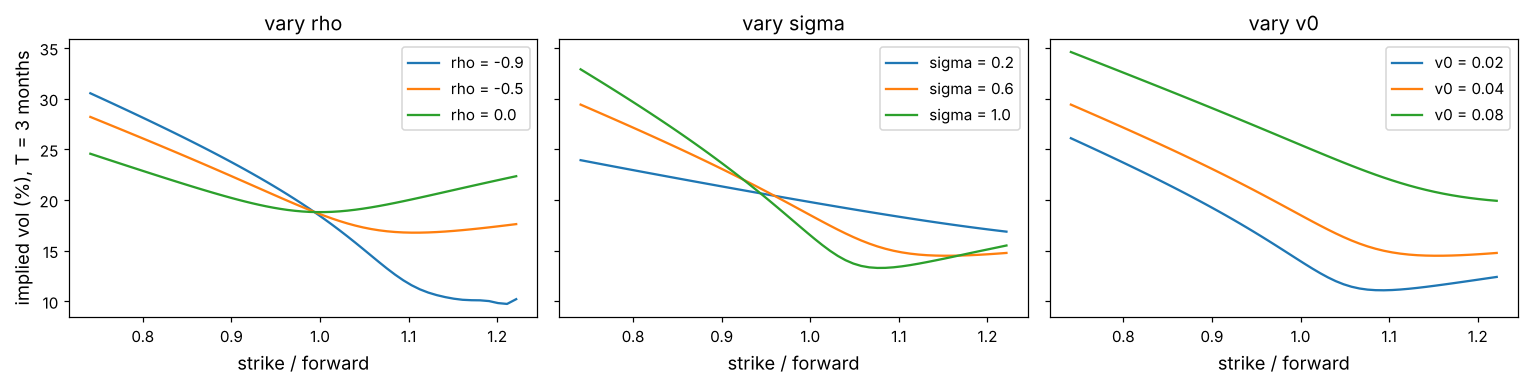

In [15]:
xg = np.linspace(-0.3, 0.2, 60); base = dict(v0=0.04, kappa=2.0, theta=0.04, sigma=0.6, rho=-0.7)
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6), sharey=True)
for a, (name, vals) in zip(ax, [("rho", [-0.9, -0.5, 0.0]), ("sigma", [0.2, 0.6, 1.0]), ("v0", [0.02, 0.04, 0.08])]):
    for val in vals:
        p = {**base, name: val}
        a.plot(np.exp(xg), 100 * heston_iv(xg, 0.25, *p.values()), label=f"{name} = {val}")
    a.set_xlabel("strike / forward"); a.legend(); a.set_title(f"vary {name}")
ax[0].set_ylabel("implied vol (%), T = 3 months")
save_fig("heston_params"); plt.show()

![Figure 8-5. How Heston's parameters shape the smile. The correlation ρ tilts it (negative ρ, expensive puts), the vol of vol σ bends it, and the initial variance v₀ moves its level.](images/heston_params.png)

### Calibrating Heston to the SPY market

**Calibration** means finding the five parameters whose implied volatilities best match the market's, here by least squares on implied volatility. The shortest expiry (17 days) is held out: we will see why.

In [16]:
cal = smile[(smile["T"] > 0.1) & (smile["x"].between(-0.3, 0.12)) & (smile["strike"] % 5 == 0)]
x_c, T_c, iv_c = cal["x"].to_numpy(), cal["T"].to_numpy(), cal["iv"].to_numpy()
LO = np.array([-1.0, 0.08, 0.005, 0.5, 0.005, 0.1, -0.95])      # box for (x/sqrt(T), T, v0, kappa, theta, sigma, rho)
HI = np.array([0.5, 1.5, 0.15, 10.0, 0.15, 2.5, 0.0])            # also the training domain of the surrogate below

def resid_exact(p):
    r_ = heston_iv(x_c, T_c, *p) - iv_c
    return np.where(np.isfinite(r_), r_, 0.5)

t0 = time.perf_counter()
fit = least_squares(resid_exact, [0.03, 2.0, 0.04, 0.8, -0.7], bounds=(LO[2:], HI[2:]))
t_exact = time.perf_counter() - t0
p_exact = fit.x
print(f"{len(cal)} options, {fit.nfev} function evaluations, {t_exact:.2f} s")
print(dict(zip(["v0", "kappa", "theta", "sigma", "rho"], p_exact.round(4))))
print(f"RMSE {100 * np.sqrt(np.mean(fit.fun**2)):.2f} vol points")
cal_err = pd.Series({e: 100 * np.sqrt(np.nanmean((heston_iv(g["x"], g["T"], *p_exact) - g["iv"])**2)) for e, g in smile[smile["x"].between(-0.3, 0.12)].groupby("expiry")})
print("RMSE by expiry (vol points):"); print(cal_err.round(2))
R.update(cal_rmse=f"{100 * np.sqrt(np.mean(fit.fun**2)):.2f}", cal_n=len(cal), cal_rho=f"{p_exact[4]:.2f}", cal_sigma=f"{p_exact[3]:.2f}",
         cal_kappa=f"{p_exact[1]:.1f}", cal_v0=f"{np.sqrt(p_exact[0]):.1%}", cal_theta=f"{np.sqrt(p_exact[2]):.1%}",
         short_rmse=f"{cal_err.iloc[0]:.1f}", feller=f"{2 * p_exact[1] * p_exact[2] - p_exact[3]**2:.2f}")

215 options, 11 function evaluations, 1.53 s
{'v0': np.float64(0.0382), 'kappa': np.float64(10.0), 'theta': np.float64(0.0441), 'sigma': np.float64(2.4247), 'rho': np.float64(-0.6986)}
RMSE 0.58 vol points
RMSE by expiry (vol points):
2026-11-20    2.43
2026-12-18    0.84
2027-01-15    0.59
2027-03-19    0.26
2027-06-17    0.10
2027-12-17    0.47
dtype: float64


The mean-reversion speed $\kappa$ has stopped at the upper edge of its box. Is the box hiding a much better fit? A **profile** answers that: fix $\kappa$ at several values, refit the other four parameters, and watch the error.

In [17]:
prof = {}
for k in [2, 5, 10, 20, 40]:
    f = least_squares(lambda q: resid_exact([q[0], k, q[1], q[2], q[3]]), [0.03, 0.04, 0.8, -0.7],
                      bounds=([1e-3, 1e-3, 0.05, -0.999], [0.25, 0.25, 8.0, 0.5]))
    prof[k] = dict(zip(["v0", "theta", "sigma", "rho"], f.x.round(3))) | {"RMSE (vol pts)": round(100 * np.sqrt(np.mean(f.fun**2)), 3)}
prof = pd.DataFrame(prof).T; prof.index.name = "kappa fixed at"
print(prof)
R["prof_5"] = f"{prof.loc[5, 'RMSE (vol pts)']:.2f}"; R["prof_40"] = f"{prof.loc[40, 'RMSE (vol pts)']:.2f}"
R["prof_best"] = str(prof["RMSE (vol pts)"].idxmin()); R["sig_5"] = f"{prof.loc[5, 'sigma']:.2f}"; R["sig_40"] = f"{prof.loc[40, 'sigma']:.1f}"

                   v0  theta  sigma    rho  RMSE (vol pts)
kappa fixed at                                            
2               0.035  0.075  1.555 -0.683           1.003
5               0.036  0.052  1.851 -0.695           0.723
10              0.038  0.044  2.425 -0.699           0.580
20              0.042  0.041  3.750 -0.694           0.606
40              0.051  0.040  6.631 -0.687           0.682


Among these values the best fit is at $\kappa$ = 10, so the box is not hiding a much better solution. But look how flat the error is: an eight-fold change of $\kappa$, from 5 to 40, moves the RMSE only between 0.72 and 0.68 vol points, while the vol of vol swings from 1.85 to 6.6 to compensate. The option prices pin down a *combination* of $\kappa$ and $\sigma$ much better than each one separately: the parameters are weakly **identified**. That is typical of calibration problems, and a reason to fix or regularise poorly identified parameters (for example, keep $\kappa$ stable from day to day) instead of reporting them with false precision.

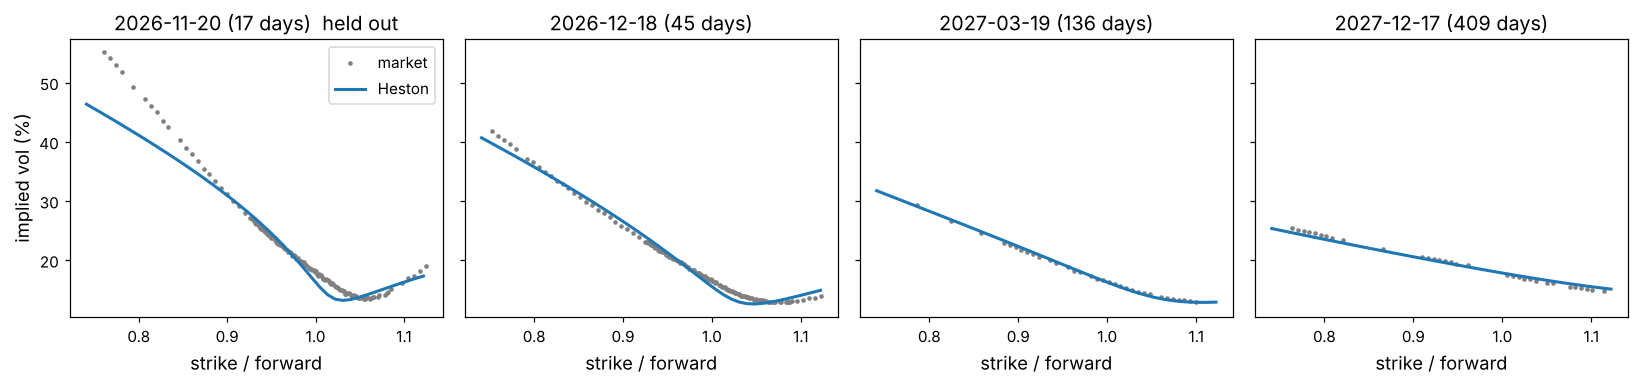

In [18]:
show = ["2026-11-20", "2026-12-18", "2027-03-19", "2027-12-17"]
fig, ax = plt.subplots(1, 4, figsize=(15, 3.6), sharey=True)
for a, e in zip(ax, show):
    g = smile[(smile["expiry"] == e) & smile["x"].between(-0.3, 0.12)]
    a.plot(g["strike"] / g["F"], 100 * g["iv"], ".", ms=4, color="0.5", label="market")
    a.plot(np.exp(xg[xg < 0.12]), 100 * heston_iv(xg[xg < 0.12], g["T"].iloc[0], *p_exact), lw=2, label="Heston")
    a.set_title(f"{e} ({g['T'].iloc[0] * 365:.0f} days)" + ("  held out" if e == show[0] else "")); a.set_xlabel("strike / forward")
ax[0].set_ylabel("implied vol (%)"); ax[0].legend()
save_fig("heston_fit"); plt.show()

![Figure 8-6. The calibrated Heston model against the market. From one month out it fits the skew well with five numbers. For the 17-day expiry, which was not used in the fit, its skew is too flat: short-dated crash protection is more expensive than a diffusion model can explain.](images/heston_fit.png)

With five parameters, Heston matches 215 market implied volatilities across five expiries with a root-mean-square error of 0.58 vol points. The calibration says: current volatility $\sqrt{v_0}$ = 19.5%, long-run volatility $\sqrt\theta$ = 21.0%, a strongly negative correlation $\rho$ = -0.70, a fast mean reversion $\kappa$ = 10.0, and a large vol of vol $\sigma$ = 2.42.

:::note
Two warnings come with these numbers. First, the held-out 17-day expiry is missed by 2.4 vol points: Heston's skew flattens too quickly as maturity shrinks, which is why practitioners add **jumps** (the Bates model) or use local or rough volatility for short maturities. Second, the **Feller condition** $2\kappa\theta \ge \sigma^2$, which keeps the variance strictly positive, is violated ($2\kappa\theta - \sigma^2$ = -5.00). That is common for equity indices: the market wants more vol of vol than a well-behaved square-root process can deliver, and the variance spends time near zero.
:::

## A neural network that replaces the pricer

The Heston calibration above took a fraction of a second because Heston has a semi-closed-form solution. Most modern models (rough volatility, models with jumps and stochastic rates, anything priced by Monte Carlo) do not, and one calibration may need millions of prices. The idea of Horvath, Muguruza and Tomas (2021) is a **surrogate**: generate prices with the slow model offline, train a neural network to map parameters to implied volatilities, and calibrate with the network. This is exactly the surrogate-modelling workflow from engineering: an expensive simulator, a training set sampled from its input space, and a fast approximation that is only trusted inside that space.

### Step 1: a training set from the exact pricer

Inputs are the seven numbers $(x/\sqrt T,\ T,\ v_0,\ \kappa,\ \theta,\ \sigma,\ \rho)$, drawn uniformly from the box `LO`–`HI` above; the output is the implied volatility. Moneyness is scaled by $\sqrt T$ so that short and long expiries cover comparable parts of their smiles.

In [19]:
def make_dataset(n, seed):
    rg = np.random.default_rng(seed); Z = LO + (HI - LO) * rg.random((n, 7))
    x = Z[:, 0] * np.sqrt(Z[:, 1]); y = np.empty(n)
    for i in range(0, n, 5000):
        sl = slice(i, i + 5000); y[sl] = heston_iv(x[sl], Z[sl, 1], *Z[sl, 2:].T)
    keep = np.isfinite(y) & (y > 0.02) & (y < 1.5)          # drop prices too small to invert reliably
    return Z[keep], y[keep]

t0 = time.perf_counter()
Z_tr, y_tr = make_dataset(200_000, seed=10); Z_te, y_te = make_dataset(20_000, seed=11)
t_gen = time.perf_counter() - t0
print(f"{len(y_tr):,} training and {len(y_te):,} test samples in {t_gen:.0f} s; implied vols from {y_tr.min():.1%} to {y_tr.max():.1%}")
R["t_gen"] = f"{t_gen:.0f}"; R["n_train"] = f"{len(y_tr):,}"

199,620 training and 19,970 test samples in 26 s; implied vols from 2.2% to 62.9%


### Step 2: a multilayer perceptron from scratch

:::math
A network with layers $h_0 = $ input, $h_{\ell} = \tanh(h_{\ell-1}W_\ell + b_\ell)$ and a linear output $\hat y = h_{L-1}W_L + b_L$. Training minimises the mean squared error $\mathcal L = \frac1n\sum(\hat y - y)^2$ by **backpropagation**, the chain rule applied layer by layer from the output back: with $g_L = \partial\mathcal L/\partial\hat y = 2(\hat y - y)/n$,

$$\frac{\partial\mathcal L}{\partial W_\ell} = h_{\ell-1}^\top g_\ell,\qquad \frac{\partial\mathcal L}{\partial b_\ell} = \textstyle\sum_{\text{rows}} g_\ell,\qquad g_{\ell-1} = (g_\ell W_\ell^\top)\odot(1 - h_{\ell-1}^2),$$

using $\tanh' = 1 - \tanh^2$. **Adam** (Kingma and Ba, 2015) then updates each parameter with running averages of its gradient $m$ and squared gradient $v$: $\theta \leftarrow \theta - \eta\,\hat m/(\sqrt{\hat v} + \epsilon)$, where hats denote bias-corrected averages. A smooth activation such as tanh matters here: it makes the network's output smooth in its inputs, so its derivatives (Greeks, calibration gradients) are smooth too.
:::

In [20]:
class MLP:
    def __init__(self, sizes, seed=0):
        rg = np.random.default_rng(seed)
        self.W = [rg.normal(0, np.sqrt(1 / a), (a, b)) for a, b in zip(sizes[:-1], sizes[1:])]
        self.b = [np.zeros(b) for b in sizes[1:]]
        self.m = [np.zeros_like(p) for p in self.W + self.b]; self.v = [np.zeros_like(p) for p in self.W + self.b]; self.t = 0

    def forward(self, X):
        self.h = [X]
        for i, (W, b) in enumerate(zip(self.W, self.b)):
            z = self.h[-1] @ W + b
            self.h.append(np.tanh(z) if i < len(self.W) - 1 else z)
        return self.h[-1][:, 0]

    def train_step(self, X, y, lr, b1=0.9, b2=0.999):
        out = self.forward(X); g = (2 * (out - y) / len(y))[:, None]
        grads_W, grads_b = [None] * len(self.W), [None] * len(self.W)
        for i in reversed(range(len(self.W))):
            grads_W[i] = self.h[i].T @ g; grads_b[i] = g.sum(0)
            if i > 0:
                g = (g @ self.W[i].T) * (1 - self.h[i]**2)
        self.t += 1
        for k, (p, gp) in enumerate(zip(self.W + self.b, grads_W + grads_b)):
            self.m[k] = b1 * self.m[k] + (1 - b1) * gp; self.v[k] = b2 * self.v[k] + (1 - b2) * gp**2
            p -= lr * (self.m[k] / (1 - b1**self.t)) / (np.sqrt(self.v[k] / (1 - b2**self.t)) + 1e-8)

scale = lambda Z: 2 * (Z - LO) / (HI - LO) - 1                  # inputs to [-1, 1]
y_mu, y_sd = y_tr.mean(), y_tr.std()                            # standardise the target
net = MLP([7, 64, 64, 64, 1]); X_tr, X_te = scale(Z_tr), scale(Z_te)
surrogate = lambda Z: net.forward(scale(np.atleast_2d(Z))) * y_sd + y_mu

epochs, batch, curve = 40, 256, []
t0 = time.perf_counter()
for ep in range(epochs):
    lr = 2e-3 * 0.5 * (1 + np.cos(np.pi * ep / epochs))         # cosine learning-rate decay
    idx = rng.permutation(len(y_tr))
    for i in range(0, len(idx), batch):
        j = idx[i:i + batch]; net.train_step(X_tr[j], (y_tr[j] - y_mu) / y_sd, lr)
    curve.append(np.sqrt(np.mean((surrogate(Z_te) - y_te)**2)))
t_train = time.perf_counter() - t0
err = np.abs(surrogate(Z_te) - y_te)
print(f"trained in {t_train:.0f} s; test RMSE {100 * curve[-1]:.3f} vol points, median {100 * np.median(err):.3f}, 99th percentile {100 * np.percentile(err, 99):.3f}")
R.update(t_train=f"{t_train:.0f}", nn_rmse=f"{100 * curve[-1]:.2f}", nn_p99=f"{100 * np.percentile(err, 99):.2f}", nn_med=f"{100 * np.median(err):.2f}")

trained in 26 s; test RMSE 0.113 vol points, median 0.046, 99th percentile 0.396


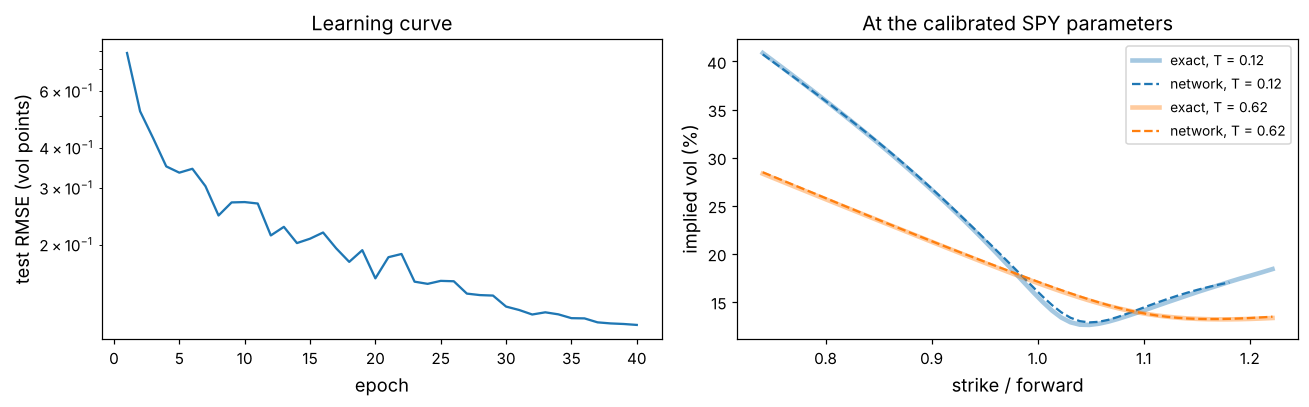

In [21]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].plot(np.arange(1, epochs + 1), 100 * np.array(curve)); ax[0].set_yscale("log")
ax[0].set_xlabel("epoch"); ax[0].set_ylabel("test RMSE (vol points)"); ax[0].set_title("Learning curve")
for T_, col in [(0.12, "tab:blue"), (0.62, "tab:orange")]:
    Zg = np.column_stack([xg / np.sqrt(T_), np.full_like(xg, T_), *[np.full_like(xg, p) for p in p_exact]])
    ok = (Zg[:, 0] >= LO[0]) & (Zg[:, 0] <= HI[0])
    ax[1].plot(np.exp(xg), 100 * heston_iv(xg, T_, *p_exact), color=col, lw=3, alpha=0.4, label=f"exact, T = {T_}")
    ax[1].plot(np.exp(xg[ok]), 100 * surrogate(Zg[ok]), "--", color=col, label=f"network, T = {T_}")
ax[1].set_xlabel("strike / forward"); ax[1].set_ylabel("implied vol (%)"); ax[1].legend(fontsize=9); ax[1].set_title("At the calibrated SPY parameters")
save_fig("surrogate"); plt.show()

![Figure 8-7. Left: test error falls steadily during training. Right: at the parameters calibrated to SPY, the network's smiles (dashed) lie on top of the exact Heston smiles.](images/surrogate.png)

The network was trained on 199,620 examples (generated in 26 s) for 26 s on a laptop CPU. On fresh test parameters its median error is 0.05 vol points and its 99th-percentile error 0.40, smaller than the bid–ask spread of most options.

### Step 3: calibrate with the network

In [22]:
Zc = lambda p: np.column_stack([x_c / np.sqrt(T_c), T_c, np.tile(p, (len(x_c), 1))])
resid_nn = lambda p: surrogate(Zc(p)) - iv_c

t0 = time.perf_counter()
fit_nn = least_squares(resid_nn, [0.03, 2.0, 0.04, 0.8, -0.7], bounds=(LO[2:], HI[2:]))
t_nn = time.perf_counter() - t0
rmse_nn_exact = 100 * np.sqrt(np.nanmean(resid_exact(fit_nn.x)**2))     # judge the network's answer with the exact pricer

t0 = time.perf_counter(); [heston_iv(x_c, T_c, *p_exact) for _ in range(20)]; t_one_exact = (time.perf_counter() - t0) / 20
t0 = time.perf_counter(); [surrogate(Zc(p_exact)) for _ in range(20)]; t_one_nn = (time.perf_counter() - t0) / 20
print(pd.DataFrame({"exact pricer": p_exact, "neural surrogate": fit_nn.x}, index=["v0", "kappa", "theta", "sigma", "rho"]).round(4))
print(f"one smile evaluation ({len(x_c)} options): exact {1e3 * t_one_exact:.1f} ms, network {1e3 * t_one_nn:.2f} ms ({t_one_exact / t_one_nn:.0f}x faster)")
print(f"calibration: exact {t_exact:.2f} s, network {t_nn:.2f} s; RMSE of the network's parameters under the exact model: {rmse_nn_exact:.2f} vol points (exact fit {100 * np.sqrt(np.mean(fit.fun**2)):.2f})")
R.update(speedup=f"{t_one_exact / t_one_nn:.0f}", rmse_nn_exact=f"{rmse_nn_exact:.2f}", t_one_exact=f"{1e3 * t_one_exact:.1f}", t_one_nn=f"{1e3 * t_one_nn:.2f}")

       exact pricer  neural surrogate
v0           0.0382            0.0360
kappa       10.0000           10.0000
theta        0.0441            0.0443
sigma        2.4247            2.4857
rho         -0.6986           -0.6995
one smile evaluation (215 options): exact 22.0 ms, network 0.24 ms (93x faster)
calibration: exact 1.53 s, network 0.03 s; RMSE of the network's parameters under the exact model: 0.61 vol points (exact fit 0.58)


One evaluation of the whole smile takes 22.0 ms with the exact Fourier pricer and 0.24 ms with the network, about 93 times faster, and the calibrated parameters, checked with the exact pricer, fit the market with an error of 0.61 vol points. For Heston, whose exact pricer is already fast, that speed-up is a convenience. For a model that needs Monte Carlo, where one smile can take seconds, the same network turns an overnight calibration into an interactive one.

:::trap
A surrogate is only as good as its training domain. Outside the box `LO`–`HI` (a vol of vol of 4, a maturity of 5 years) the network extrapolates with no warning, and a calibration routine that wanders there returns nonsense with full confidence. Calibrate within the same bounds you trained on, check the final answer with the exact model as we did, and retrain when the market moves to the edge of the box. The SPY calibration already sits at the edge: $\kappa$ on the upper bound of 10 and the vol of vol, 2.42, close to 2.5. A production system would widen the box and retrain.
:::

## Present your solution

- **What worked.** Four pricing methods that agree with one another (tree, formula, Monte Carlo, Fourier); implied volatilities computed from raw trade prices with parity-implied forwards; a calibrated Heston model that fits SPY from one month to 13 months with an average error of 0.58 vol points; and a from-scratch neural network that reproduces it.
- **What the data say.** The SPY volatility skew is steep and persistent. Over 33 years, implied variance exceeded realised variance in 83% of months; the premium is real but its skewness (-6.4) shows it is compensation for crash risk, not free money.
- **Limitations.** One snapshot of the option chain, last-trade prices instead of synchronised quotes, the variance swap approximated by VIX on SPX against realised variance on SPY, and no transaction costs (option spreads are wide, often several percent of the premium for out-of-the-money options).

## Launch, monitor and maintain

A pricing model in production is a system that runs all day, not a notebook that runs once.

- **Recalibrate on a schedule** (every few minutes while the market is open) and log every result. Alarm on the calibration RMSE by expiry and on parameter jumps: a vol of vol that doubles between two calibrations usually means bad input quotes, not a new market.
- **Guard the surrogate.** Before using the network, check that the parameters and inputs lie inside the training box, with a margin; outside it, fall back to the exact pricer and schedule a retraining on a widened box.
- **Explain the P&L every day.** Decompose the book's P&L into delta, gamma, theta and vega contributions using the Greeks from the start of the day. The part nothing explains is the most important number on the risk report: it is where model error, bad data and booking mistakes show up.
- **Limit the tails.** For a short-volatility book, set limits on total vega and run stress tests (the index −20% with VIX at 80, as in October 2008 or March 2020) instead of trusting the Sharpe ratio.

## Try it out

::playground animations/options_lab.html 760

Three tabs: the Black–Scholes price and Greeks as you move spot, volatility and time to expiry; a delta-hedging simulator in which you choose the implied and realised volatility and how often to rebalance; and the Heston smile, with the 3-month SPY market smile from the chain above to fit by hand.

## Exercises

:::exercise
1. Use the tree to find the **early-exercise boundary** of an American put (the highest spot at which immediate exercise is optimal) at each time step, and plot it against time to expiry.
2. Price an arithmetic-average **Asian** call by Monte Carlo, using the geometric-average Asian call (which has a closed form) as a control variate. How much does the standard error fall?
3. Repeat the delta-hedging experiment with **transaction costs** of 2 basis points per share traded. How does the optimal rebalancing frequency change?
4. Split the variance-risk-premium backtest by the level of VIX at entry (below 15, 15–25, above 25). When is selling variance most profitable, and when is it most dangerous?
5. Train the surrogate on 25,000, 50,000, 100,000 and 200,000 samples and plot test RMSE against training-set size. What does the curve suggest about the value of more data versus a larger network?
:::

<details><summary>Solutions</summary>

In [23]:
# 4
vs["vix_bucket"] = pd.cut(100 * np.sqrt(vs["implied_var"]), [0, 15, 25, 100], labels=["VIX < 15", "15-25", "> 25"])
print(vs.groupby("vix_bucket", observed=True)["pnl"].agg(months="count", mean="mean", worst="min",
      win_rate=lambda s: (s > 0).mean()).round(4))

# 5
sizes = [25_000, 50_000, 100_000, 200_000]; rmse_by_n = {}
for n in sizes:
    n = min(n, len(y_tr))
    net5 = MLP([7, 64, 64, 64, 1], seed=1); Xn, yn = X_tr[:n], (y_tr[:n] - y_mu) / y_sd
    n_ep = int(epochs * len(y_tr) / n / 4)              # the same number of updates for every n (a quarter of the main run)
    for ep in range(n_ep):
        lr = 2e-3 * 0.5 * (1 + np.cos(np.pi * ep / n_ep)); idx = rng.permutation(n)
        for i in range(0, n, batch):
            j = idx[i:i + batch]; net5.train_step(Xn[j], yn[j], lr)
    rmse_by_n[n] = 100 * np.sqrt(np.mean((net5.forward(X_te) * y_sd + y_mu - y_te)**2))
print({k: round(v, 3) for k, v in rmse_by_n.items()})

            months    mean   worst  win_rate
vix_bucket                                  
VIX < 15       134  0.0047 -0.0689    0.8209
15-25          203  0.0086 -0.2088    0.8276
> 25            67  0.0186 -0.6066    0.8358


{25000: np.float64(0.248), 50000: np.float64(0.243), 100000: np.float64(0.253), 199620: np.float64(0.228)}


With a quarter of the main run's gradient updates, every training-set size ends near the same error, about twice the main run's. In this regime the error is limited by **optimisation** (how long we train) and network capacity, not by the amount of data: 25,000 Heston smiles already cover the seven-dimensional box well enough for a network of this size. More data pays off only once training is long enough and the network large enough to use it.

</details>

## What's next

So far we have assumed that trades happen at the price on the screen. Chapter 9 looks inside the market: the order book, why large orders move prices, how to split a big trade optimally (Almgren–Chriss), how market makers set their quotes (Avellaneda–Stoikov), and a reinforcement-learning agent that learns to trade in a simulated order book.

In [24]:
# data for the playground: the 3-month SPY smile and the calibrated parameters
Path("animations").mkdir(exist_ok=True)
g = smile[(smile["expiry"] == "2027-03-19") & smile["x"].between(-0.3, 0.12)]
payload = {"expiry": "2027-03-19", "T": round(float(g["T"].iloc[0]), 4),
           "x": [round(float(v), 4) for v in g["x"]], "iv": [round(float(v), 4) for v in g["iv"]],
           "fit": dict(zip(["v0", "kappa", "theta", "sigma", "rho"], [round(float(v), 4) for v in p_exact]))}
Path("animations/data.js").write_text("window.OPTIONS_DATA = " + json.dumps(payload) + ";\n")
print(len(payload["x"]), payload["fit"])

33 {'v0': 0.0382, 'kappa': 10.0, 'theta': 0.0441, 'sigma': 2.4247, 'rho': -0.6986}
